# 🌍 → 🌕 / 🔴  TerraX
A LightGBM model that predicts whether a place on Earth is a **Moon analog**, a **Mars analog**, or **neither**.

Space agencies train astronauts and test rovers at places on Earth that resemble the Moon or Mars, such as Meteor Crater and the Atacama Desert. This notebook learns what those places have in common from NASA data, then scores **any** coordinate, for example `Moon 0.62 · Mars 0.25 · Neither 0.13`.

| Section | Content |
|---|---|
| 1 | Setup |
| 2 | Labelled places (`data/sites.csv`) |
| 3 | Data: NASA imagery, terrain, climate, surface temperature, vegetation, PDS spectra, geology |
| 4 | Features |
| 5 | Look at the data |
| 6 | Model (LightGBM) |
| 7 | Evaluation on unseen places |
| 8 | Feature importance |
| 9 | Predict new places |
| 10 | Export the model for the website (`webapp/`) |

---
## 1. Setup
**Libraries:** `requests` (web APIs), `numpy` and `pandas`, `Pillow` (images), `lightgbm` (model), `scikit-learn` (evaluation), `matplotlib` (charts).

Every download is cached in `data/cache/`, so re-runs are fast.

In [288]:
import json, time, re
from pathlib import Path

import numpy as np
import pandas as pd
import requests
from PIL import Image
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, log_loss, confusion_matrix, classification_report

In [289]:
PATCH_HALF_DEG  = 0.10     # area around each place: +/-0.1 deg (~ +/-11 km)
PATCH_PX        = 48       # image is 48 x 48 pixels (~460 m / pixel)
PIXELS_PER_SITE = 200      # training pixels sampled per place
SEED            = 42

CLASSES = ["Moon", "Mars", "Neither"]                       # class 0, 1, 2
COLORS  = {"Moon": "#2a78d6", "Mars": "#eb6834", "Neither": "#1baf7a"}   # fixed colour per class

DATA = Path("..") / "data"; DATA.mkdir(exist_ok=True)       # the notebook lives in model/, the data one level up
CACHE = DATA / "cache"; CACHE.mkdir(exist_ok=True)
HEADERS = {"User-Agent": "terrax/0.1"}

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#888", "axes.labelcolor": "#333", "xtick.color": "#555",
                     "ytick.color": "#555", "axes.grid": True, "grid.color": "#eee"})

---
## 2. Labelled places
| Class | What it means |
|---|---|
| **Moon** | Apollo/Artemis training and lunar test sites: impact craters, fresh basalt lava, cinder fields |
| **Mars** | Mars rover tests, crewed simulations and astrobiology sites: hyper-arid, cold, salty or acidic deserts |
| **Neither** | ordinary land: forests, cities, farmland, wetlands, and dry steppe and scrub (so "dry" alone isn't enough) |

The places are read from **`data/sites.csv`**, with the columns `site, lat, lon, label, region, source`. The labels come mainly from the ESA/Open University *Catalogue of Planetary Analogues* (Preston et al., 2012) and the USGS record of Apollo astronaut field training (Open-File Report 2005-1190, Table 1), plus NASA, JPL, USGS and peer-reviewed sources for the remaining sites. Every place has its reference in the `source` column.

**Only analogs you can see from orbit:** some documented analogs, such as the Sudbury and Ries impact craters, are valued for their *rocks*, but at this resolution (about 460 m per pixel) their surroundings are forest or farmland. They are left out, because the model would otherwise learn that green land can be an analog.

**Spatial groups:** places closer than 150 km share a `group`. Testing never trains on a place and then tests on its near neighbour.

In [290]:
from scipy.sparse.csgraph import connected_components

sites = pd.read_csv(DATA / "sites.csv")

# spatial groups: link every pair of places closer than 150 km, then take the connected clusters
lat, lon = np.radians(sites.lat.values), np.radians(sites.lon.values)
dlat, dlon = lat[:, None] - lat[None, :], lon[:, None] - lon[None, :]
dist_km = 6371 * 2 * np.arcsin(np.sqrt(np.sin(dlat / 2) ** 2 + np.cos(lat[:, None]) * np.cos(lat[None, :]) * np.sin(dlon / 2) ** 2))
_, sites["group"] = connected_components(dist_km < 150, directed=False)

print(sites.label.value_counts().to_string())
sites.head()

label
Mars       48
Neither    39
Moon       38


,site,lat,lon,label,region,source,group
0,"Meteor Crater, Arizona",35.03,-111.02,Moon,"Meteor Crater, Arizona",Catalogue of Planetary Analogues (Preston et a...,0
1,"Cinder Lake Crater Field, AZ",35.29,-111.47,Moon,"Cinder Lake Crater Field, AZ",Catalogue of Planetary Analogues (Preston et a...,0
2,"Black Point Lava Flow, AZ",35.70,-111.46,Moon,"Black Point Lava Flow, AZ",Catalogue of Planetary Analogues (Preston et a...,0
3,"Craters of the Moon, Idaho",43.42,-113.52,Moon,"Craters of the Moon, Idaho",USGS OFR 2005-1190 Table 1 (Apollo training) 1969,1
4,"Sudbury Basin, Ontario",46.60,-81.00,Moon,"Sudbury Basin, Ontario",Catalogue of Planetary Analogues (Preston et a...,2


---
## 3. Data
| Source | What it gives | Why it matters |
|---|---|---|
| **Blue Marble** (NASA GIBS, 500 m) | true surface colour | red iron oxide (Mars), dark basalt (Moon), green vegetation (Neither) |
| **ASTER DEM shaded relief** (GIBS) | terrain shape | craters, lava and canyons are rough |
| **NASA POWER** climatology | temperature, humidity, sunlight | analogs are dry, with harsh temperature swings |
| **PDS RELAB** spectra (3d) | lab spectra of Moon and Mars samples | the real colour of the Moon and Mars |
| **MODIS surface temperature** (GIBS, 3e) | daytime ground temperature in two seasons | how strongly the ground heats and cools |
| **MODIS vegetation index (NDVI)** (GIBS, 3f) | how green the ground is at the peak of summer | analogs are deserts, hot or polar, with almost no plants even in summer |
| **Macrostrat geologic maps** (3g) | rock type | basalt and impact rock (Moon-like) vs sediments and salts (Mars-like) |

GIBS is the image service behind [Worldview](https://worldview.earthdata.nasa.gov), so every layer can also be viewed there.

In [291]:
# resources
GIBS_WMS = "https://gibs.earthdata.nasa.gov/wms/epsg4326/best/wms.cgi"
POWER    = "https://power.larc.nasa.gov/api/temporal/climatology/point"
RELAB = "https://pds-geosciences.wustl.edu/speclib/urn-nasa-pds-relab/data_reflectance"
LST_COLORMAP_URL = "https://gibs.earthdata.nasa.gov/colormaps/v1.3/MODIS_Land_Surface_Temp.xml"
NDVI_COLORMAP_URL = "https://gibs.earthdata.nasa.gov/colormaps/v1.3/MODIS_NDVI.xml"
MACROSTRAT = "https://macrostrat.org/api/v2/geologic_units/map"

In [292]:

POWER_PARAMS = ["T2M", "T2M_MAX", "T2M_MIN", "RH2M", "ALLSKY_SFC_SW_DWN"]

def _get(url, params=None, expect=None, tries=4):
    # GET with simple retry (APIs sometimes time out).
    # expect = required start of the Content-Type (e.g. "image"), so an error page is never saved as data.
    for i in range(tries):
        try:
            r = requests.get(url, params=params, headers=HEADERS, timeout=60)
            if r.status_code == 200 and (expect is None or r.headers.get("Content-Type", "").startswith(expect)):
                return r
        except requests.RequestException:
            pass
        time.sleep(2 ** i)
    raise RuntimeError(f"failed: {url} {params}")

def gibs_patch(layer, lat, lon, half=PATCH_HALF_DEG, px=PATCH_PX, date=None):
    # Download a small square image (px x px) of a GIBS layer centred on lat/lon.
    # date: for layers that change over time, e.g. "2023-07-01" (None = the layer's default).
    # Returns float array (px, px, 4) = R,G,B,Alpha in 0..1. Cached on disk.
    tag = f"_{date}" if date else ""
    f = CACHE / f"{layer}{tag}_{lat:.3f}_{lon:.3f}_{half}_{px}.png"
    if not f.exists():
        params = dict(SERVICE="WMS", REQUEST="GetMap", VERSION="1.3.0", LAYERS=layer,
                      CRS="EPSG:4326", STYLES="", FORMAT="image/png", WIDTH=px, HEIGHT=px,
                      BBOX=f"{lat-half},{lon-half},{lat+half},{lon+half}")   # WMS 1.3: lat,lon order
        if date:
            params["TIME"] = date
        f.write_bytes(_get(GIBS_WMS, params, expect="image").content)
    return np.asarray(Image.open(f).convert("RGBA"), dtype=np.float32) / 255.0

def power_climate(lat, lon):
    # Long-term annual climate averages from NASA POWER. Cached on disk.
    f = CACHE / f"power_{lat:.3f}_{lon:.3f}.json"
    if not f.exists():
        r = _get(POWER, dict(parameters=",".join(POWER_PARAMS), community="AG",
                             latitude=lat, longitude=lon, format="JSON"), expect="application/json")
        f.write_text(r.text, encoding="utf-8")
    p = json.loads(f.read_text(encoding="utf-8"))["properties"]["parameter"]
    return {k: (np.nan if p[k]["ANN"] == -999 else p[k]["ANN"]) for k in POWER_PARAMS}

### Look at a few places
Colour (top row) and terrain relief (bottom row) for two places per class.

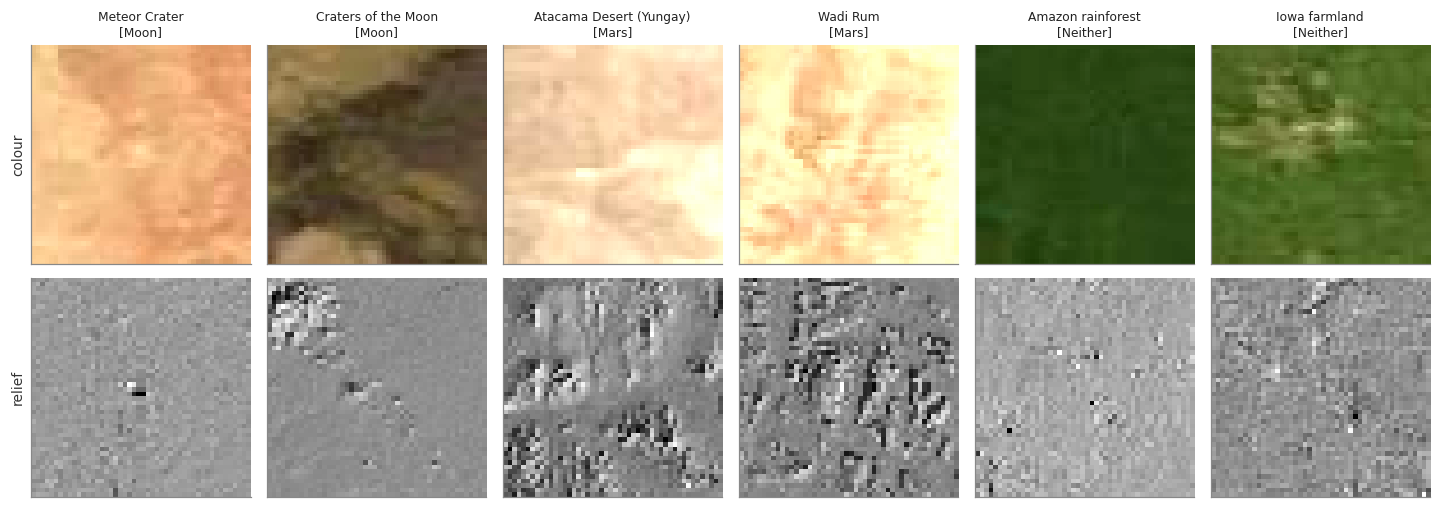

In [293]:
show = ["Meteor Crater, Arizona", "Craters of the Moon, Idaho", "Atacama Desert (Yungay), Chile",
        "Wadi Rum, Jordan", "Amazon rainforest, Brazil", "Iowa farmland, USA"]

fig, axes = plt.subplots(2, len(show), figsize=(2.2 * len(show), 4.8))
for j, name in enumerate(show):
    s = sites.set_index("site").loc[name]
    c = gibs_patch("BlueMarble_NextGeneration", s.lat, s.lon)
    h = gibs_patch("ASTER_GDEM_Greyscale_Shaded_Relief", s.lat, s.lon)

    axes[0, j].imshow(np.clip(c[..., :3] * 1.8, 0, 1))      # brightened for display only
    axes[1, j].imshow(h[..., 0], cmap="gray")
    axes[0, j].set_title(f"{name.split(',')[0]}\n[{s.label}]", fontsize=8, color="#222")
    for a in axes[:, j]: a.set_xticks([]); a.set_yticks([]); a.grid(False)

axes[0, 0].set_ylabel("colour", fontsize=9); axes[1, 0].set_ylabel("relief", fontsize=9)
plt.tight_layout(); plt.show()

---
### PDS reference spectra (RELAB)
The PDS Geosciences Node hosts **RELAB**, a library of laboratory reflectance spectra. A spectrum shows how much light a material reflects at each wavelength.

| Reference | Samples |
|---|---|
| `moon_soil` | 14 Apollo soils: dark mare and bright highland |
| `mars_dust` | 5 × JSC Mars-1, NASA's simulant of red Martian dust |
| `mars_rock` | 7 Martian meteorites |

Each spectrum is averaged over the three MODIS bands that Blue Marble is built from (blue, green and red). Its colour **shape** is then described by two numbers: `slope_rg = ln(R/G)` and `slope_gb = ln(G/B)`. Every Earth pixel gets the same two numbers. Blue Marble is a display image, so it's first converted back to approximate reflectance (by undoing the sRGB gamma).

In [294]:
# folder/spectrum_id : sample name (from the PDS label)
PDS_SPECTRA = {
    "moon_soil": {
        "bdr2/c1lr15": "Apollo 11 mare soil 10084",   "bdr2/c1lr10": "Apollo 12 mare soil 12001",
        "bdr2/c1lr30": "Apollo 12 mare soil 12030",   "bdr3/c2lr80": "Apollo 15 mare soil 15071",
        "bdr2/c1lr23": "Apollo 17 mare soil 70181",   "bdr2/c1lr28": "Apollo 17 mare soil 71501",
        "bdr3/c1lr41": "Apollo 17 mare soil 79221",   "bdr3/c1lr59": "Apollo 17 mare soil 71061",
        "bdr3/c1lr104": "Apollo 16 highland soil 62231", "bdr3/c1lr112": "Apollo 16 highland soil 61141",
        "bdr3/c1ls110": "Apollo 16 highland soil 64421", "bdr3/c1ls115": "Apollo 16 highland soil 67461",
        "bdr2/c1ls128": "Apollo 16 highland soil 67511", "bdr3/c1lr89": "Apollo 14 soil 14163",
    },
    "mars_dust": {
        "bdr2/c1jb239a": "JSC Mars-1 (A)", "bdr2/c1jb240a": "JSC Mars-1 (B)", "bdr3/c1jb521a": "JSC Mars-1 palagonite",
        "bdr3/c1jbh86a": "JSC Mars-1 <125 um", "bdr3/c1jb569a": "JSC Mars-1 (C)",
    },
    "mars_rock": {
        "bdr3/c1mt223p": "Tissint", "bdr3/c1mt224p": "NWA 1068", "bdr3/c1mt225p": "NWA 2626",
        "bdr3/c1mt226p": "NWA 6234", "bdr3/c1mt227p": "NWA 6963", "bdr3/c1mt228p": "NWA 7397",
        "bdr3/c1mt04a": "EETA79001",
    },
}
MODIS_BANDS = {"R": (620, 670), "G": (545, 565), "B": (459, 479)}   # MODIS bands 1, 4, 3 (nm)

def relab_spectrum(path):
    # Download one RELAB spectrum (.tab) from the PDS. Returns wavelength (nm), reflectance (0..1).
    f = CACHE / f"relab_{path.replace('/', '_')}.tab"
    if not f.exists():
        f.write_text(_get(f"{RELAB}/{path}.tab").text, encoding="utf-8")
    lines = f.read_text(encoding="utf-8").splitlines()
    n = int(lines[0].split()[0])                       # first line = number of data rows
    rows = [l.split()[:2] for l in lines[1:] if len(l.split()) >= 2][:n]
    a = np.array(rows, dtype=float)
    return a[:, 0], a[:, 1]

def band_values(wl, refl):
    # average reflectance inside each MODIS band -> [R, G, B]
    return np.array([refl[(wl >= lo) & (wl <= hi)].mean() for lo, hi in MODIS_BANDS.values()])

def colour_shape(rgb):
    # brightness-independent colour shape: [ln(R/G), ln(G/B)]
    return np.array([np.log(rgb[0] / rgb[1]), np.log(rgb[1] / rgb[2])])

def srgb_to_linear(v):
    # undo the standard display brightness curve (sRGB gamma) -> roughly proportional to reflectance
    return np.where(v <= 0.04045, v / 12.92, ((v + 0.055) / 1.055) ** 2.4)

REF_RGB   = {k: np.mean([band_values(*relab_spectrum(p)) for p in d], axis=0) for k, d in PDS_SPECTRA.items()}
REF_SHAPE = {k: colour_shape(v) for k, v in REF_RGB.items()}
pd.DataFrame({k: {"red": v[0], "green": v[1], "blue": v[2], "red/green": v[0] / v[1], "green/blue": v[1] / v[2]}
              for k, v in REF_RGB.items()}).T.round(3)

,red,green,blue,red/green,green/blue
moon_soil,0.156,0.141,0.124,1.111,1.138
mars_dust,0.216,0.122,0.051,1.770,2.379
mars_rock,0.357,0.336,0.279,1.064,1.204


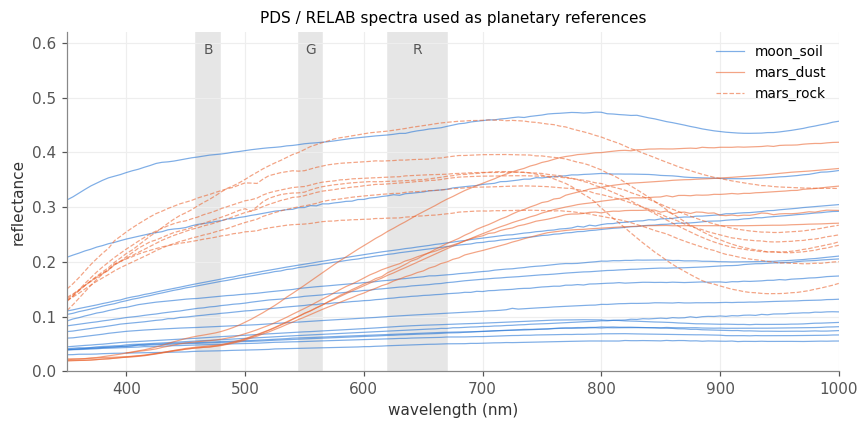

In [295]:
STYLE = {"moon_soil": dict(color=COLORS["Moon"], ls="-"), "mars_dust": dict(color=COLORS["Mars"], ls="-"),
         "mars_rock": dict(color=COLORS["Mars"], ls="--")}
fig, ax = plt.subplots(figsize=(8, 4))
for name, (lo, hi) in MODIS_BANDS.items():
    ax.axvspan(lo, hi, color="#e6e6e6", zorder=0)
    ax.text((lo + hi) / 2, 0.58, name, ha="center", fontsize=9, color="#555")
for k, d in PDS_SPECTRA.items():
    for j, p in enumerate(d):
        wl, refl = relab_spectrum(p)
        keep = (wl >= 350) & (wl <= 1000)
        ax.plot(wl[keep], refl[keep], lw=0.8, alpha=0.6, label=k if j == 0 else None, **STYLE[k])
ax.set_xlim(350, 1000); ax.set_ylim(0, 0.62)
ax.set_xlabel("wavelength (nm)"); ax.set_ylabel("reflectance")
ax.set_title("PDS / RELAB spectra used as planetary references", fontsize=10)
ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

---
### Surface temperature
Dry, bare ground heats and cools far more than vegetated or wet ground; LRO Diviner measured this behaviour on the Moon. On Earth we use **MODIS land surface temperature**: monthly daytime maps for January and July 2023 from GIBS. GIBS serves them as coloured images, so each colour is converted back to kelvin using the published colormap.

| Feature | Meaning |
|---|---|
| `lst_season` | July − January daytime ground temperature (K): how strongly the ground heats and cools over the year |


In [ ]:
LST_MONTHS = ["2023-01-01", "2023-07-01"]

cmf = CACHE / "MODIS_Land_Surface_Temp_colormap.xml"
if not cmf.exists():
    cmf.write_text(_get(LST_COLORMAP_URL).text, encoding="utf-8")
entries = re.findall(r'rgb="(\d+),(\d+),(\d+)"[^>]*?value="\[([\d.]+),([\d.]+)\)"', cmf.read_text(encoding="utf-8"))
CM_RGB = np.array([[int(r), int(g), int(b)] for r, g, b, _, _ in entries], dtype=np.float32) / 255
CM_K   = np.array([(float(lo) + float(hi)) / 2 for *_, lo, hi in entries])
CM_K[0], CM_K[-1] = 200.0, 350.0          # the first/last bins are open-ended (<200 K, >350 K)

def decode_lst(img):
    # colour image (px,px,4) -> temperature in kelvin (px,px); NaN where there is no data
    rgb = img[..., :3].reshape(-1, 1, 3)
    dist = ((rgb - CM_RGB[None]) ** 2).sum(-1)               # distance to every colormap colour
    k = CM_K[dist.argmin(1)].reshape(img.shape[:2])          # nearest colour -> its temperature
    nodata = (img[..., 3] == 0) | (dist.min(1).reshape(img.shape[:2]) > 0.003)
    return np.where(nodata, np.nan, k)

def lst_season(lat, lon):
    # July - January daytime ground temperature (K), per pixel
    jan, jul = [decode_lst(gibs_patch("MODIS_Terra_L3_Land_Surface_Temp_Monthly_Day", lat, lon, date=m)) for m in LST_MONTHS]
    return np.abs(jul - jan)                                 # abs: the seasons are reversed in the south

---
### Vegetation (summer greenness)
Every analog is some kind of desert: hot (Atacama, Sahara) or polar (Svalbard, Antarctic valleys), with almost no plants even in summer. Ordinary land, including tundra, turns green in summer. A single colour image like Blue Marble can't show that, so we add the **MODIS vegetation index (NDVI)**: monthly maps for January and July 2023 from GIBS. NDVI runs from 0 (bare ground, snow) to 1 (dense forest). GIBS serves it as a coloured image, so each colour is converted back to NDVI with the published colormap, the same way as the surface temperature. Values of 0 or below are drawn transparent, so a transparent land pixel means no vegetation.

| Feature | Meaning |
|---|---|
| `ndvi_peak` | peak-season greenness of each pixel: the higher of January and July, so it works in both hemispheres |
| `patch_ndvi` | average `ndvi_peak` over the whole ±11 km area |

In [297]:
NDVI_MONTHS = ["2023-01-01", "2023-07-01"]

ndf = CACHE / "MODIS_NDVI_colormap.xml"
if not ndf.exists():
    ndf.write_text(_get(NDVI_COLORMAP_URL).text, encoding="utf-8")
entries = re.findall(r'rgb="(\d+),(\d+),(\d+)" transparent="false"[^>]*?value="\[([\d.]+),([\d.]+)\)"', ndf.read_text(encoding="utf-8"))
NDVI_RGB = np.array([[int(r), int(g), int(b)] for r, g, b, _, _ in entries], dtype=np.float32) / 255
NDVI_VAL = np.array([(float(lo) + float(hi)) / 2 for *_, lo, hi in entries])

def decode_ndvi(img):
    # colour image (px,px,4) -> NDVI (px,px); transparent pixels are NDVI <= 0 (bare ground, snow) -> 0
    rgb = img[..., :3].reshape(-1, 1, 3)
    v = NDVI_VAL[((rgb - NDVI_RGB[None]) ** 2).sum(-1).argmin(1)].reshape(img.shape[:2])   # nearest colour -> its NDVI
    return np.where(img[..., 3] == 0, 0.0, v)

def ndvi_peak(lat, lon):
    # peak-season greenness per pixel: the higher of January and July (summer in either hemisphere)
    jan, jul = [decode_ndvi(gibs_patch("MODIS_Terra_L3_NDVI_Monthly", lat, lon, date=m)) for m in NDVI_MONTHS]
    return np.maximum(jan, jul)

---
### Rock type (geologic maps)
The rock under a place is the most direct link to the Moon or Mars: basalt and impact rock are lunar-like, while sediments, salts and clays point to Mars's watery past. **[Macrostrat](https://macrostrat.org)** (University of Wisconsin) combines the geologic maps of national geological surveys into one free API. Several maps can cover the same point and sometimes disagree, so for the centre of each place every map unit returned **votes** (more detailed maps get more votes). Each rock description is sorted into one of 10 classes, for example `mafic_volcanic` (basalt), `evaporite` (salt, gypsum), `clastic_sediment` (sandstone, shale) or `impact`.

The feature `rock` is **categorical**, and LightGBM handles categories directly.

In [298]:
# rock classes, checked in this order; the first class with a matching keyword wins
ROCK_RULES = [
    ("impact",           ["impact", "breccia", "suevite"]),
    ("evaporite",        ["evaporite", "salt", "gypsum", "halite", "playa", "saline", "sabkha", "sebkha"]),
    ("mafic_volcanic",   ["basalt", "basaltic", "mafic volcanic", "lava"]),
    ("felsic_volcanic",  ["rhyolite", "dacite", "tuff", "ignimbrite", "andesite", "felsic volcanic", "pyroclastic"]),
    ("volcanic",         ["volcanic"]),
    ("intrusive",        ["granite", "gabbro", "anorthosite", "diorite", "intrusive", "plutonic", "granodiorite", "syenite"]),
    ("metamorphic",      ["gneiss", "schist", "metamorphic", "quartzite", "marble", "amphibolite", "greenstone"]),
    ("carbonate",        ["limestone", "dolomite", "carbonate", "chalk", "travertine"]),
    ("unconsolidated",   ["alluvium", "alluvial", "unconsolidated", "sand", "gravel", "dune", "loess", "colluvium", "till", "glacial", "eolian", "aeolian"]),
    ("clastic_sediment", ["sandstone", "shale", "siltstone", "conglomerate", "mudstone", "sedimentary", "siliciclastic", "clastic"]),
]
ROCK_CLASSES = [cls for cls, _ in ROCK_RULES] + ["unknown"]
SCALE_WEIGHT = {"large": 4, "medium": 3, "small": 2, "tiny": 1}     # votes per map unit: more detailed map = more votes

def classify_unit(u):
    # rock class of one map unit (whole words only, so "salt" does not match inside "basalt")
    text = f"{u.get('lith', '')} {u.get('name', '')}".lower()
    for cls, words in ROCK_RULES:
        if any(re.search(r"\b" + re.escape(w) + r"\b", text) for w in words):
            return cls
    return None

def rock_type(lat, lon):
    # Rock class at the centre of a place. Several geologic maps can cover the same point and may disagree,
    # so every map unit votes for its class; more detailed maps get more votes. Cached on disk.
    f = CACHE / f"macrostrat_{lat:.3f}_{lon:.3f}.json"
    if not f.exists():
        f.write_text(_get(MACROSTRAT, dict(lat=lat, lng=lon), expect="application/json").text, encoding="utf-8")
    votes = {}
    for u in json.loads(f.read_text(encoding="utf-8")).get("success", {}).get("data", []):
        cls = classify_unit(u)
        if cls:
            votes[cls] = votes.get(cls, 0) + SCALE_WEIGHT.get(u.get("scale"), 1)
    return max(votes, key=votes.get) if votes else "unknown"

---
## 4. Features
Each pixel (about 460 m) becomes one row of numbers. With 200 pixels per place, 110 places give 22,000 rows.

| Features | From | Meaning |
|---|---|---|
| `b`, `brightness` | colour | dark basalt vs bright sand or salt |
| `slope_rg`, `slope_gb` | colour shape (3d) | lunar grey vs Martian red |
| `patch_roughness`, `patch_color_var` | the whole ±11 km area | rugged, patchy terrain |
| `patch_slope_gb` | average of `slope_gb` over the area | the overall colour of the place; steadier than a single pixel |
| `T2M`, `temp_range`, `RH2M`, `ALLSKY_SFC_SW_DWN` | NASA POWER | temperature, temperature swing, humidity and sunlight |
| `lst_season` | surface temperature (3e) | seasonal heating and cooling of the ground |
| `ndvi_peak`, `patch_ndvi` | vegetation index (3f) | summer greenness of the pixel and of the whole area |
| `rock` | geologic map (3g) | rock class at the centre of the place (categorical) |

Water pixels are dropped. Latitude and longitude are **not** features, so the model learns what a place is like, not where it is.

In [299]:
def place_features(lat, lon):
    # Return a DataFrame with one row per land pixel around lat/lon.
    c = gibs_patch("BlueMarble_NextGeneration", lat, lon)                 # colour (48,48,4)
    relief = gibs_patch("ASTER_GDEM_Greyscale_Shaded_Relief", lat, lon)[..., 0]   # terrain (48,48)
    r, g, b, alpha = c[..., 0], c[..., 1], c[..., 2], c[..., 3]
    brightness = (r + g + b) / 3
    lin = srgb_to_linear(c[..., :3]) + 1e-3                  # approx. reflectance; +1e-3 avoids log(0)
    f = {
        "b": b,
        "brightness": brightness,
        "slope_rg": np.log(lin[..., 0] / lin[..., 1]),       # ln(red/green)
        "slope_gb": np.log(lin[..., 1] / lin[..., 2]),       # ln(green/blue)
        "lst_season": lst_season(lat, lon),          # seasonal ground-temperature swing (K)
        "ndvi_peak": ndvi_peak(lat, lon),            # summer greenness (0 = bare, 1 = dense forest)
    }
    df = pd.DataFrame({k: v.ravel() for k, v in f.items()})
    water = (b > r) & (b > g) & (brightness < 0.35)
    df = df[((alpha > 0) & ~water).ravel()].reset_index(drop=True)   # keep land pixels only
    # whole-area context (same value for every pixel of this place)
    df["patch_roughness"] = relief.std()
    df["patch_color_var"] = brightness.std()
    df["patch_slope_gb"] = df["slope_gb"].mean()            # average colour shape of the whole area
    df["patch_ndvi"] = df["ndvi_peak"].mean()               # average summer greenness of the whole area
    # climate (same value for every pixel of this place)
    clim = power_climate(lat, lon)
    for k, v in clim.items():
        df[k] = v
    df["temp_range"] = clim["T2M_MAX"] - clim["T2M_MIN"]
    # geology (same value for every pixel of this place)
    df["rock"] = pd.Categorical([rock_type(lat, lon)] * len(df), categories=ROCK_CLASSES)
    return df

FEATURES = [
    "b", "brightness", "slope_rg", "slope_gb",                     # colour
    "patch_roughness", "patch_color_var", "patch_slope_gb",       # area context
    "T2M", "temp_range", "RH2M", "ALLSKY_SFC_SW_DWN",             # climate
    "lst_season",                                                  # surface temperature
    "ndvi_peak", "patch_ndvi",                                     # vegetation
    "rock",                                                        # geology (categorical)
]

### Build the training table
For every place: compute the features, keep 200 random land pixels, and add the label and group. The first run downloads about 1,000 small files (5–15 minutes); later runs use the cache.

In [300]:
rows = []
for i, s in enumerate(sites.itertuples(), 1):
    df = place_features(s.lat, s.lon)
    if len(df) > PIXELS_PER_SITE:
        df = df.sample(PIXELS_PER_SITE, random_state=SEED)
    df["site"], df["label"], df["group"] = s.site, s.label, s.group
    rows.append(df)
    print(f"\r{i}/{len(sites)} {s.site[:40]:40s} {len(df)} pixels", end="")
    
train = pd.concat(rows, ignore_index=True)
train["y"] = train.label.map({c: i for i, c in enumerate(CLASSES)})
print("\n", train.shape)
train.groupby("label").size()

125/125 Klyuchevskaya volcano group, Kamchatka   200 pixels
 (25000, 21)


label
Mars       9600
Moon       7600
Neither    7800
dtype: int64

---
## 5. Look at the data
One value per place (the average of its pixels). If a feature's boxes sit at different heights, that feature helps tell the classes apart. Dashed lines are the PDS references.

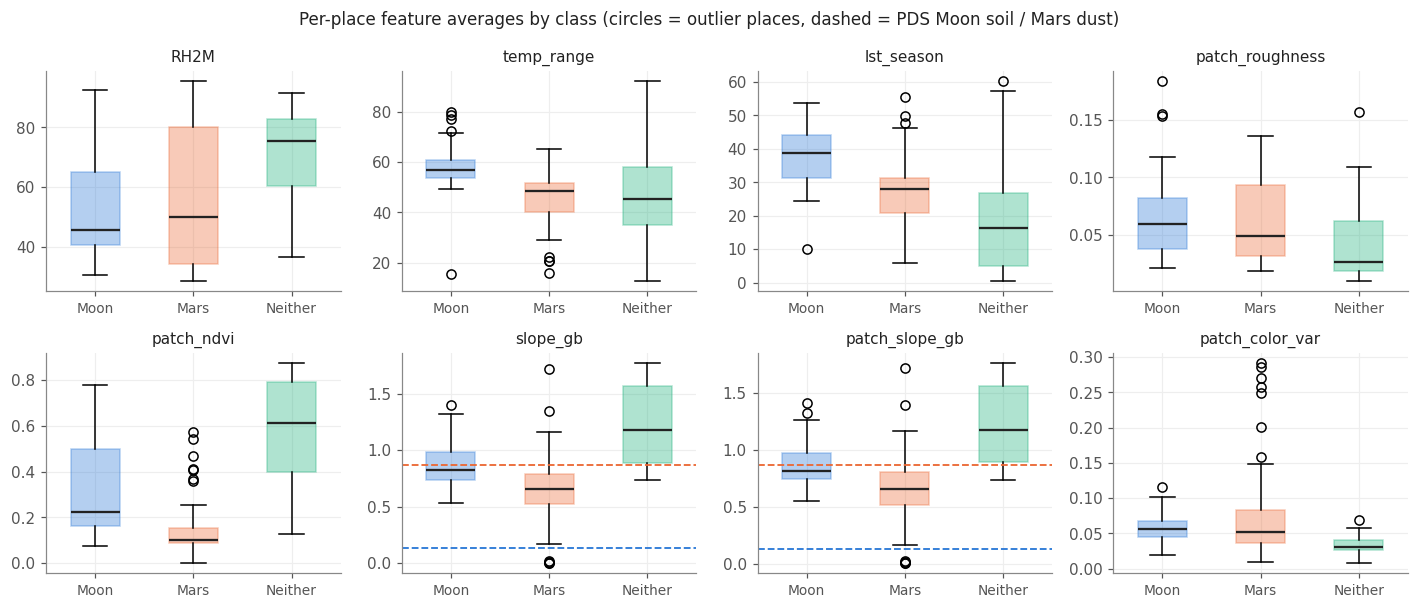

In [301]:
NUMERIC = [f for f in FEATURES if f != "rock"]
site_means = train.groupby(["site", "label"])[NUMERIC].mean().reset_index()
show_feats = ["RH2M", "temp_range", "lst_season", "patch_roughness", "patch_ndvi", "slope_gb", "patch_slope_gb", "patch_color_var"]
fig, axes = plt.subplots(2, 4, figsize=(13, 5.6))

for ax, feat in zip(axes.ravel(), show_feats):
    data = [site_means.loc[site_means.label == c, feat].dropna() for c in CLASSES]   # boxplot can't handle NaN
    bp = ax.boxplot(data, widths=0.5, patch_artist=True, showfliers=True,
                    medianprops=dict(color="#222", linewidth=1.5))
    for patch, c in zip(bp["boxes"], CLASSES):
        patch.set_facecolor(COLORS[c]); patch.set_alpha(0.35); patch.set_edgecolor(COLORS[c])
    ax.set_xticks([1, 2, 3], CLASSES, fontsize=9); ax.set_title(feat, fontsize=10, color="#222")
    if feat in ("slope_gb", "patch_slope_gb"):                     # PDS reference values as dashed lines (G/B)
        ax.axhline(REF_SHAPE["moon_soil"][1], color=COLORS["Moon"], ls="--", lw=1.2)
        ax.axhline(REF_SHAPE["mars_dust"][1], color=COLORS["Mars"], ls="--", lw=1.2)

fig.suptitle("Per-place feature averages by class (circles = outlier places, dashed = PDS Moon soil / Mars dust)", fontsize=11, color="#222")
plt.tight_layout(); plt.show()

**What it shows:**
- Humidity (`RH2M`) is far lower at analogs (median about 44 % at Mars sites and 42 % at Moon sites) than at ordinary places (about 76 %).
- Moon analogs have the widest yearly temperature range (`temp_range`); analogs are also more rugged (`patch_roughness`) and patchier (`patch_color_var`).
- The ground's seasonal temperature swing (`lst_season`) is largest at Moon analogs (median about 40 K), then Mars analogs (about 28 K), and smallest at ordinary places (about 17 K).
- Summer greenness (`patch_ndvi`) separates analogs from ordinary land most clearly: median about 0.10 at Mars sites and 0.17 at Moon sites, against 0.61 at ordinary places. Analogs are deserts, hot or polar.
- `slope_gb`: Earth's Moon analogs are *redder* than its Mars analogs, and far redder than real lunar soil (the blue dashed line). Many Moon sites are red cinder fields, while several Mars sites are grey basalt or white salt. The area average (`patch_slope_gb`) separates the classes more cleanly than single pixels.

---
## 6. Model: LightGBM
LightGBM builds many small decision trees one after another, and each tree corrects the mistakes of the previous ones. It handles features with very different scales and outputs one probability per class.

The settings keep the model simple: tiny trees, big leaves and only 30 % of the features per tree. It can't lean on a single feature or memorise individual places, which keeps its probabilities honest.

| Setting | Value | Meaning |
|---|---|---|
| `n_estimators` | 200 | number of trees |
| `learning_rate` | 0.05 | how much each tree contributes |
| `num_leaves` | 2 | each tree is a single yes/no rule |
| `min_child_samples` | 12 × pixels per place (2,400) | each rule must hold for at least about 12 places |
| `subsample` | 1.0 | each tree sees all pixels |
| `colsample_bytree` | 0.3 | each tree sees a random 30 % of the features, so no single feature dominates |
| `reg_lambda` | 5 | shrinks extreme leaf values |
| `min_split_gain` | 0.5 | a rule is only added if it clearly helps |
| `class_weight` | balanced | every class counts equally |

In [302]:
def make_model():
    return lgb.LGBMClassifier(
        objective="multiclass", n_estimators=200, learning_rate=0.05, num_leaves=2,
        min_child_samples=PIXELS_PER_SITE * 12,          # each rule must hold for about 12 places
        subsample=1.0, colsample_bytree=0.3, reg_lambda=5.0, min_split_gain=0.5,
        class_weight="balanced", random_state=SEED, verbose=-1)

X, y, groups = train[FEATURES], train["y"], train["group"]          # whole spatial groups stay together in testing
make_model()

,num_leaves,2
,learning_rate,0.05
,n_estimators,200
,objective,'multiclass'
,class_weight,'balanced'
,min_split_gain,0.5
,min_child_samples,2400
,colsample_bytree,0.3
,reg_lambda,5.0
,random_state,42
,verbose,-1


---
## 7. Evaluation on unseen places
Pixels of the same place are near-copies, so a random pixel split would leak answers. `StratifiedGroupKFold` instead holds out whole **spatial groups** in each of 5 folds: it trains on the rest and predicts the held-out places. Pixel probabilities are then averaged per place.

**Metrics:** accuracy, and **log-loss**, which measures how trustworthy the probabilities are (lower is better).

In [303]:
def grouped_cv(features, seed=SEED):
    # 5-fold cross-validation where all pixels of a place stay together.
    # Returns pixel probabilities (oof) and the per-place table (place).
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    oof = np.zeros((len(train), len(CLASSES)))          # out-of-fold probabilities
    for tr, te in cv.split(train, y, groups):
        m = make_model().fit(train.iloc[tr][features], y.iloc[tr])
        oof[te] = m.predict_proba(train.iloc[te][features])
    place = (pd.DataFrame(oof, columns=CLASSES).assign(site=train.site.values, label=train.label.values)
             .groupby(["site", "label"], sort=False)[CLASSES].mean().reset_index())   # average pixels per place
    place["predicted"] = place[CLASSES].idxmax(axis=1)
    return oof, place

oof, place = grouped_cv(FEATURES)
print(f"PIXEL level  accuracy {accuracy_score(y, oof.argmax(1)):.3f}   log-loss {log_loss(y, oof):.3f}")
print(f"PLACE level  accuracy {(place.predicted == place.label).mean():.3f}  ({len(place)} places)\n")
print(classification_report(place.label, place.predicted, labels=CLASSES, zero_division=0))

PIXEL level  accuracy 0.818   log-loss 0.480
PLACE level  accuracy 0.840  (125 places)

              precision    recall  f1-score   support

        Moon       0.82      0.87      0.85        38
        Mars       0.93      0.81      0.87        48
     Neither       0.77      0.85      0.80        39

    accuracy                           0.84       125
   macro avg       0.84      0.84      0.84       125
weighted avg       0.85      0.84      0.84       125



### Confusion matrix
Rows are the true class and columns are the prediction. Moon ↔ Mars confusions are expected, because several sites are analogs for both.

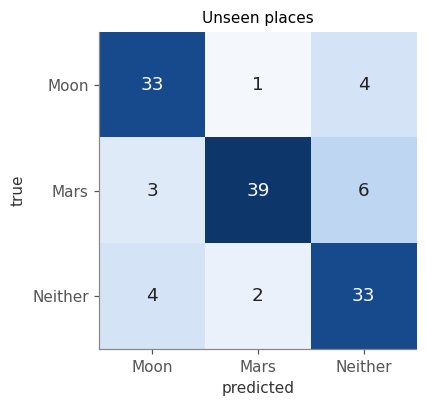

In [304]:
cm = confusion_matrix(place.label, place.predicted, labels=CLASSES)
fig, ax = plt.subplots(figsize=(4.4, 3.8))
ax.imshow(cm, cmap=plt.matplotlib.colors.LinearSegmentedColormap.from_list("b", ["#f4f8fd", "#2a78d6", "#0d366b"]))
for i in range(3):
    for j in range(3):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=12,
                color="white" if cm[i, j] > cm.max() / 2 else "#222")
ax.set_xticks(range(3), CLASSES); ax.set_yticks(range(3), CLASSES); ax.grid(False)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("Unseen places", fontsize=10)
plt.tight_layout(); plt.show()

---
## 8. Feature importance
The final model is trained on all places. Importance (gain) is how much each feature reduced the model's error. It shows what the model *uses*, not cause and effect.

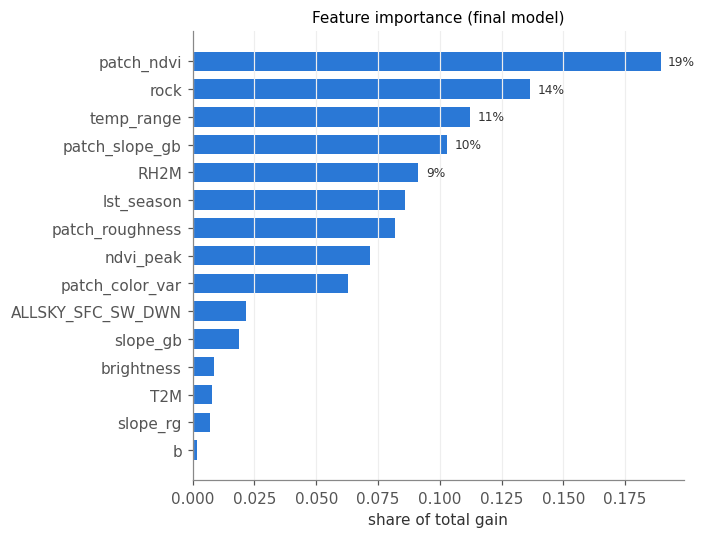

In [305]:
model = make_model().fit(X, y)
imp = pd.Series(model.booster_.feature_importance("gain"), index=FEATURES).sort_values()
imp = imp / imp.sum()
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.barh(imp.index, imp.values, color=COLORS["Moon"], height=0.7)
for i, v in enumerate(imp.values):
    if v >= imp.values[-5]:
        ax.text(v + 0.003, i, f"{v:.0%}", va="center", fontsize=8, color="#333")
ax.set_xlabel("share of total gain"); ax.set_title("Feature importance (final model)", fontsize=10)
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**What it shows:**
- Importance is **spread across many features**. Each tree only sees 30 % of the features, so the model can't lean on one of them.
- **`patch_ndvi`**, the summer greenness of the whole area, is by far the strongest feature (about 27 %), and the per-pixel `ndvi_peak` adds about 10 %. Greenness is the clearest *analog vs not* signal: analogs are deserts, hot or polar, where almost nothing grows even in summer.
- Humidity (`RH2M`, about 12 %), **`rock`** (about 11 %) and the temperature range (about 10 %) follow. Sedimentary rock points to Mars, while basalt, intrusive rock and impact rock lean towards the Moon; rock type is the feature that helps Moon vs Mars the most, because it's real geology, not appearance.
- **`patch_slope_gb`**, the average colour shape of the whole area (about 9 %), follows the labels (Earth's Moon sites are redder than its Mars sites), so part of what it learns is the typical colour of each region, not of the real Moon or Mars.
- Colour patchiness, sunlight and terrain roughness add the rest of the picture. Single-pixel colour (`b`, `brightness`, `slope_rg`), the seasonal ground-temperature swing and mean temperature (`T2M`) play only a small role, because greenness and humidity already carry most of what they told the model.

---
## 9. Predict any place
`predict_place(lat, lon)` downloads the data for a location, computes the features and averages the pixel probabilities. It also maps which pixels look most Moon-like or Mars-like. Below are places that are not in the training list.

**Both Moon and Mars:** some places resemble both worlds; for example, the Catalogue describes Atacama, Iceland and Meteor Crater as analogues for both. When the Moon and Mars probabilities are **each at least 30 %** (`BOTH_MIN`) **and each higher than Neither**, the verdict is **Both** instead of the single highest class. The second condition keeps uncertain places, where all three classes are close, from being called Both. The model itself still predicts three classes; "Both" is read from its probabilities. On unseen places this verdict is uncommon: about 8 of the 110 training places on average (4 to 10 depending on the split), and never for ordinary land.

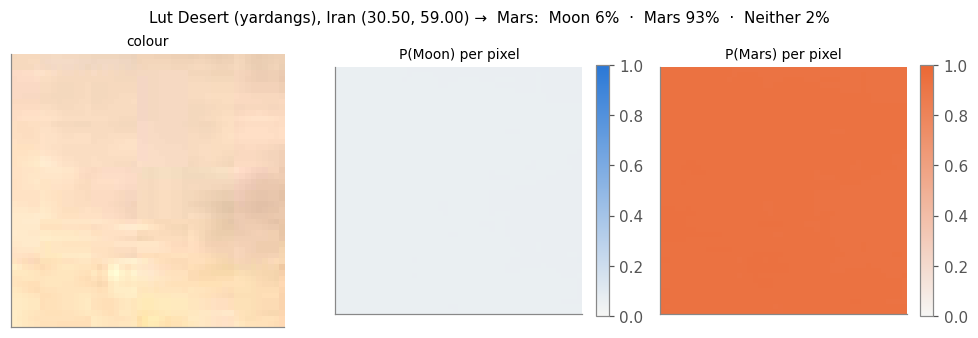

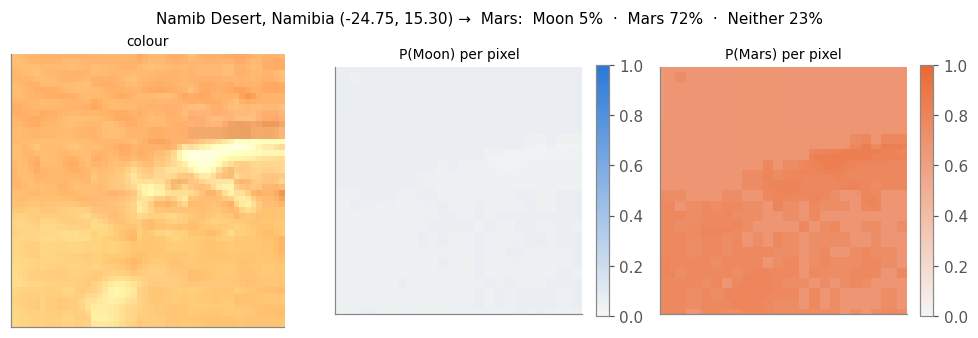

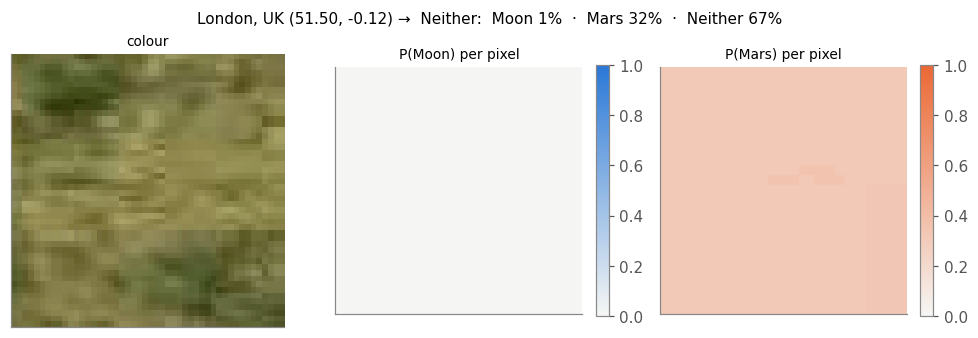

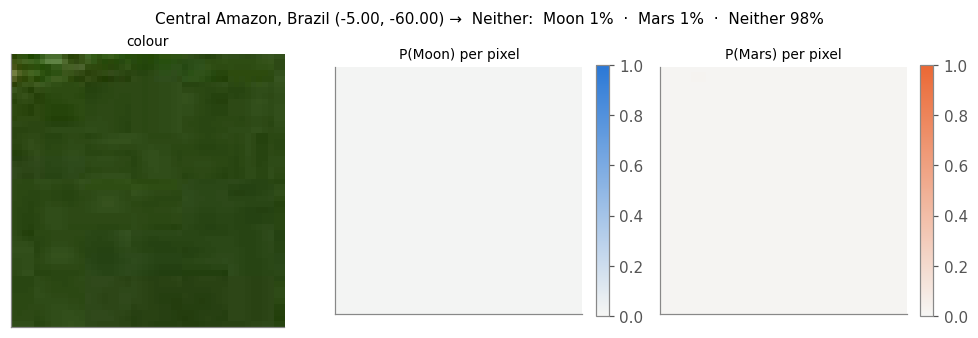

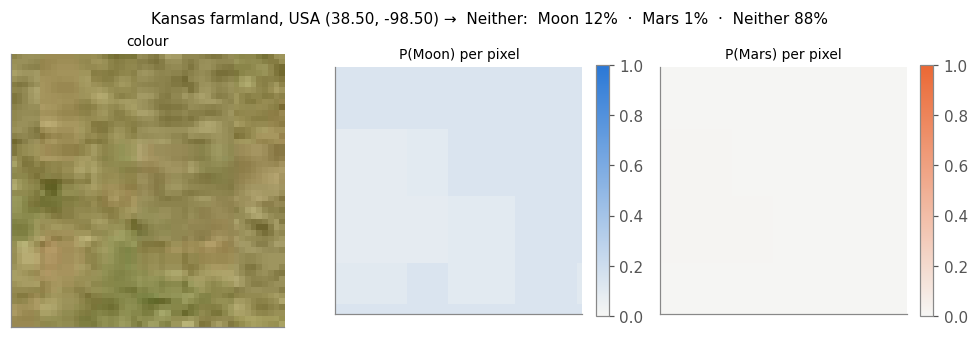

,place,Moon,Mars,Neither,verdict
0,"Lut Desert (yardangs), Iran",0.059,0.926,0.016,Mars
1,"Namib Desert, Namibia",0.051,0.715,0.234,Mars
2,"London, UK",0.006,0.325,0.669,Neither
3,"Central Amazon, Brazil",0.012,0.010,0.978,Neither
4,"Kansas farmland, USA",0.118,0.008,0.875,Neither


In [306]:
BOTH_MIN = 0.30      # Moon and Mars both at least this probability (and both above Neither) -> verdict "Both"

def verdict(result):
    # result = {"Moon": p, "Mars": p, "Neither": p} -> "Moon", "Mars", "Neither" or "Both"
    moon, mars, neither = result["Moon"], result["Mars"], result["Neither"]
    if moon >= BOTH_MIN and mars >= BOTH_MIN and min(moon, mars) > neither:
        return "Both"
    return max(result, key=result.get)

def predict_place(lat, lon, name=None, plot=True):
    df = place_features(lat, lon)
    if df.empty:
        print("no land pixels here"); return None
    proba = model.predict_proba(df[FEATURES])
    result = dict(zip(CLASSES, proba.mean(0).round(3)))
    if plot:
        c = gibs_patch("BlueMarble_NextGeneration", lat, lon)
        b, r_, g_ = c[..., 2], c[..., 0], c[..., 1]
        bright = c[..., :3].mean(-1)
        valid = (c[..., 3] > 0) & ~((b > r_) & (b > g_) & (bright < 0.35))
        fig, axes = plt.subplots(1, 3, figsize=(9, 3.1))
        axes[0].imshow(np.clip(c[..., :3] * 1.8, 0, 1)); axes[0].set_title("colour", fontsize=9)
        for ax, cls in zip(axes[1:], ["Moon", "Mars"]):
            grid = np.full(valid.shape, np.nan); grid[valid] = proba[:, CLASSES.index(cls)]
            cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list(cls, ["#f6f6f4", COLORS[cls]])
            im = ax.imshow(grid, vmin=0, vmax=1, cmap=cmap); ax.set_title(f"P({cls}) per pixel", fontsize=9)
            fig.colorbar(im, ax=ax, fraction=0.046)
        for ax in axes: ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        fig.suptitle(f"{name or ''} ({lat:.2f}, {lon:.2f}) →  {verdict(result)}:  " +
                     "  ·  ".join(f"{k} {v:.0%}" for k, v in result.items()), fontsize=10)
        plt.tight_layout(); plt.show()
    return result

TEST_PLACES = [
    ("Lut Desert (yardangs), Iran",   30.50,   59.00),
    ("Namib Desert, Namibia",        -24.75,   15.30),
    ("London, UK",                    51.50,   -0.12),
    ("Central Amazon, Brazil",        -5.00,  -60.00),
    ("Kansas farmland, USA",          38.50,  -98.50),
]
results = []
for name, lat, lon in TEST_PLACES:
    res = predict_place(lat, lon, name)
    results.append({"place": name, **res, "verdict": verdict(res)})
pd.DataFrame(results)

---
## 10. Export for the website
The website (`webapp/`) lets you click any place on an interactive map and get a prediction with a characterisation card. This cell saves what it needs into `data/`: the trained model, the feature list, the typical conditions of the known analogs, and the known sites.

**Run the website** from the project folder (one level above `model/`): `python webapp/app.py`, then open <http://localhost:5000>.

In [307]:
import joblib

NUMERIC = [f for f in FEATURES if f != "rock"]
SHOWN = ["rock", "RH2M", "temp_range", "lst_season", "patch_ndvi", "patch_roughness", "patch_slope_gb"]

# typical conditions of the known Moon / Mars analogs, and every analog's profile (for "most similar site")
place_vals = train.groupby(["site", "label"]).agg({**{f: "median" for f in NUMERIC}, "rock": "first"}).reset_index()
typical = {lab: {f: (str(g[f].mode()[0]) if f == "rock" else float(g[f].median())) for f in SHOWN}
           for lab, g in place_vals.groupby("label")}
meta = {
    "features": FEATURES, "classes": CLASSES, "rock_classes": ROCK_CLASSES, "typical": typical, "both_min": BOTH_MIN,
    "mu": place_vals[NUMERIC].mean().to_dict(), "sd": place_vals[NUMERIC].std().to_dict(),
    "analogs": place_vals[place_vals.label.isin(["Moon", "Mars"])][["site", "label"] + NUMERIC].to_dict("records"),
}

joblib.dump(model, DATA / "analog_model.joblib")                                   # the trained model
(DATA / "web_meta.json").write_text(json.dumps(meta, indent=1), encoding="utf-8")   # settings + reference values
sites[["site", "lat", "lon", "label"]].to_json(DATA / "web_sites.json", orient="records")
print("saved for the website:", ", ".join(["analog_model.joblib", "web_meta.json", "web_sites.json"]))

saved for the website: analog_model.joblib, web_meta.json, web_sites.json
